# 32 · Evals in CI: a release gate that blocks a bad change
Level L6 · Part 6 · core · ~35 min · builds on 07, 08

## Goal
Run the golden set on every change, compare the score with a saved baseline, and fail the build when the score drops. The gate is a pytest test
that CI runs; this notebook runs it the same way. A deliberately worse agent is then blocked. Evals here use a scripted agent, so the gate itself
is what is tested, and it costs no model calls.

## Why it matters
A prompt tweak, a new model or a new tool can make the agent worse on cases nobody looked at. Without a gate, the regression reaches customers,
and it is found by a complaint. With a gate, the change is measured on the same 30 tasks before it merges, and a drop is refused.

| No gate | With a release gate |
|---|---|
| A change is judged by a few hand-tried questions | A change is judged on the golden set, the same every time |
| A drop is found by customers | A drop fails the build, with the tasks that failed named |
| The score is in someone's head | The baseline is a file in the repository |

## The idea
The **golden set** is the list of tasks with their expected end states (lesson 07). The **baseline** is the score of the last accepted version,
saved to a file. The **gate** compares the score of the new version with the baseline; a drop beyond the allowed amount fails the check. CI runs
the gate on every change; a **canary** sends a new version to a small share of traffic first and compares it with the old one.

## Picture
`show_mermaid` is a small helper in the topic folder (`graph_view.py`). It draws a Mermaid flowchart, so you can read the gate's logic before the code.

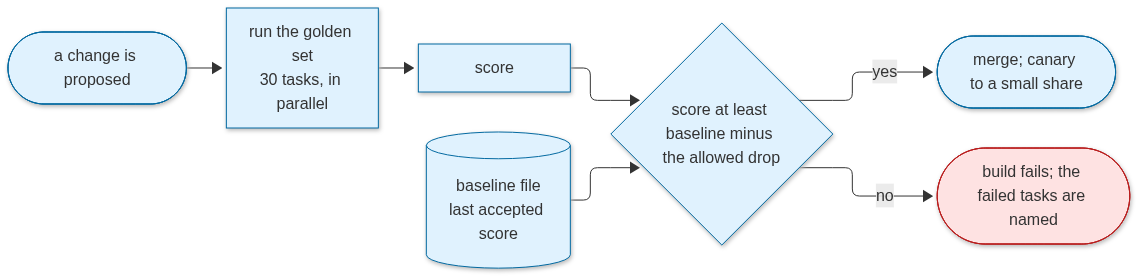

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  C(["a change is proposed"]) --> R["run the golden set<br/>30 tasks, in parallel"]
  R --> S["score"]
  B[("baseline file<br/>last accepted score")] --> G{"score at least baseline minus the allowed drop"}
  S --> G
  G -->|yes| M(["merge; canary to a small share"])
  G -->|no| X(["build fails; the failed tasks are named"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef stop fill:#fee2e2,stroke:#b91c1c
  class C,R,S,B,G,M code
  class X stop
""")

## Step by step
Four steps, then a fifth that shows two ways a gate goes wrong. No step calls the model.

**Step 1 · the golden set and the baseline (no call).** The 30 golden tasks come from `data/support_eval.json`: 30 hand-written support questions
about fictional orders, made for this course (no personal data). Each task has a request, the tools it must call, the tools it must not call, and
its expected end state. The agent here is the scripted stand-in from lesson 07: it looks up any order it finds in the request and refunds nothing.

In [2]:
import json
import operator
import re
from pathlib import Path
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import END, START, StateGraph
from langgraph.types import Send

DATA = json.loads((Path("../../../data") / "support_eval.json").read_text())
TASKS = DATA["tasks"]
LAB = Path("../../../data/lg32").resolve()  # absolute: the gate runs from inside this folder
LAB.mkdir(parents=True, exist_ok=True)
print(TASKS[0]["request"], TASKS[0]["must_call"], TASKS[0]["expected_end"])

Where is my parcel for order 1002? It was due on Monday. ['lookup_order'] {'refunds': {}, 'tickets': []}


`grade` decides one task: it fails the task if a forbidden tool was called, a required tool was skipped, or the end state differs.
`scripted_agent` is the stand-in agent. `RunState` is the state of the eval graph; its results from all branches are added together.

In [3]:
def grade(task: dict, end: dict, called: list[str]) -> tuple[bool, str]:
    if any(t in called for t in task.get("forbidden_tools", [])):
        return False, "called a forbidden tool"
    if any(t not in called for t in task.get("must_call", [])):
        return False, "skipped a required tool"
    if end != task["expected_end"]:
        return False, "end state differs"
    return True, "ok"


def scripted_agent(request: str):
    return {"refunds": {}, "tickets": []}, (["lookup_order"] if re.search(r"\b\d{4}\b", request) else [])


class RunState(TypedDict):
    results: Annotated[list, operator.add]
    score: str

`run_suite` runs the eval graph. `Send` is LangGraph's way to start one branch per item: here each task goes to the `case` node, all at once,
and `score` counts the passes. It returns the passed count, the total and the failed task ids. `agent` is the version under test.

In [4]:
def run_suite(agent) -> dict:
    """The eval graph: one branch per task, all at once, then the score. `agent` is the version under test."""
    def fan_out(state):
        return [Send("case", {"task": t}) for t in TASKS]

    def case(inp):
        task = inp["task"]
        end, called = agent(task["request"])
        ok, why = grade(task, end, called)
        return {"results": [{"id": task["id"], "passed": ok, "why": why}]}

    def score(state):
        passed = sum(r["passed"] for r in state["results"])
        return {"score": f"{passed}/{len(state['results'])}"}

    g = StateGraph(RunState)
    g.add_node("case", case)
    g.add_node("score", score)
    g.add_conditional_edges(START, fan_out, ["case"])
    g.add_edge("case", "score").add_edge("score", END)
    out = g.compile().invoke({"results": [], "score": ""})
    return {"passed": sum(r["passed"] for r in out["results"]), "total": len(out["results"]),
            "failed": sorted(r["id"] for r in out["results"] if not r["passed"])}

Save the baseline. `baseline.json` holds the passed count and the allowed drop (zero here: no drop is allowed). `candidate.json` is the version
under test, which CI writes on each change; here it starts as the same run.

In [5]:
baseline_run = run_suite(scripted_agent)
(LAB / "baseline.json").write_text(json.dumps({"passed": baseline_run["passed"], "total": baseline_run["total"],
                                             "allowed_drop": 0}, indent=2))
(LAB / "candidate.json").write_text(json.dumps(baseline_run, indent=2))
print("baseline:", baseline_run["passed"], "of", baseline_run["total"])

baseline: 12 of 30


**Step 2 · the gate, as a pytest test (no call).** The gate is a test file. It reads the baseline and the candidate's results, and fails when the
candidate's score is below the baseline minus the allowed drop. The test names the tasks that failed, so the author knows where to look. The
file is written from this notebook so it can run here; in a repository it would be committed.

In [6]:
GATE = '''"""Release gate: the candidate may not score below the baseline minus the allowed drop."""
import json
from pathlib import Path

LAB = Path(__file__).parent


def test_score_holds_the_baseline():
    base = json.loads((LAB / "baseline.json").read_text())
    cand = json.loads((LAB / "candidate.json").read_text())
    floor = base["passed"] - base["allowed_drop"]
    assert cand["passed"] >= floor, (
        f"score {cand['passed']}/{cand['total']} is below the floor {floor}; failed tasks: {cand['failed']}")
'''
(LAB / "test_release_gate.py").write_text(GATE)
print("wrote test_release_gate.py with", GATE.count("def test_"), "test")

wrote test_release_gate.py with 1 test


`run_gate` runs pytest on that file the way CI does. It returns the exit code (0 passes, non-zero fails) and pytest's last line.

In [7]:
import subprocess
import sys as _sys


def run_gate() -> tuple[int, str]:
    out = subprocess.run([_sys.executable, "-m", "pytest", "-q", "--color=no", str(LAB / "test_release_gate.py")],
                         capture_output=True, text=True, cwd=str(LAB))
    last = [line for line in (out.stdout + out.stderr).splitlines() if line.strip()][-1]
    return out.returncode, last


code, line = run_gate()
print("gate with the current candidate: exit", code, "·", line[:120])

gate with the current candidate: exit 0 · 1 passed in 0.01s


**Step 3 · a change that makes the agent worse (no call).** A candidate that stops looking up orders fails the tasks that need a lookup. The
gate is run on it, and the build fails. The candidate file is overwritten by the new run, as CI does on each change.

In [8]:
def worse_agent(request: str):
    end, called = scripted_agent(request)
    return end, []  # the change removed the lookup: every task that needs one now fails


bad = run_suite(worse_agent)
(LAB / "candidate.json").write_text(json.dumps(bad, indent=2))
code, line = run_gate()
print("gate with the worse candidate: exit", code, "·", line[:160])
print("failed tasks:", bad["failed"][:8], "…" if len(bad["failed"]) > 8 else "")

gate with the worse candidate: exit 1 · 1 failed in 0.05s
failed tasks: ['t01', 't02', 't03', 't04', 't05', 't06', 't07', 't08'] …


**Step 4 · put the candidate back (no call).** The good candidate is restored and the gate passes again. The exit code is what CI reads: zero
merges, non-zero blocks.

In [9]:
(LAB / "candidate.json").write_text(json.dumps(baseline_run, indent=2))
code, line = run_gate()
print("gate after restoring the candidate: exit", code, "·", line[:120])

gate after restoring the candidate: exit 0 · 1 passed in 0.01s


**Step 5 · two ways a gate goes wrong (no call).** Both are run for real. (a) The baseline is moved to the worse run, so the same gate passes it.
(b) A gate prints the failure but never sets a non-zero exit code, so the build still passes.

In [10]:
moved = LAB / "moved_baseline"  # a copy of the gate with its own files; the real baseline is not touched
moved.mkdir(exist_ok=True)
(moved / "test_release_gate.py").write_text(GATE)
(moved / "baseline.json").write_text(json.dumps({"passed": bad["passed"], "total": bad["total"], "allowed_drop": 0}))
(moved / "candidate.json").write_text(json.dumps(bad))
out = subprocess.run([_sys.executable, "-m", "pytest", "-q", "--color=no", str(moved / "test_release_gate.py")],
                     capture_output=True, text=True, cwd=str(moved))
print("(a) baseline moved to the worse run: exit", out.returncode)

(a) baseline moved to the worse run: exit 0


(b) is the second mistake: the gate's message is built and printed, but nothing turns it into a failing exit code.

In [11]:
msg = f"FAIL: score {bad['passed']}/{bad['total']} is below the floor"
noisy = subprocess.run([_sys.executable, "-c", f"print({msg!r})"], capture_output=True, text=True)
print("(b) print-only gate: exit", noisy.returncode, "·", noisy.stdout.strip())

(b) print-only gate: exit 0 · FAIL: score 2/30 is below the floor


## At real scale
- **The golden set runs in CI on every pull request.** The baseline lives in the repository; a change to it is reviewed like a change to a test.
  Traces show why a task failed: lesson 33.
- **Rollout: rainbow, shadow and canary.** Anthropic describes rainbow deployments for long-running agents: in-flight runs keep the old version
  ([Anthropic, multi-agent research system](https://www.anthropic.com/engineering/multi-agent-research-system)). A canary sends a small share of
  traffic to the new version first; lesson 37 runs one on a real fleet.
- **What breaks first: the golden set goes stale.** Once the agent passes every task, the gate tells you nothing new, so real failures must be
  added to the set. (The lesson's own reasoning, not a sourced number.)
- **A gate on the score is not enough alone.** It must also check the safety tasks: the injected tickets from lesson 07.

## Decision guide

| Situation | Recommended approach | Why |
|---|---|---|
| A prompt or tool-description change | Run the golden set in CI; gate on the baseline | The same tasks every time show what the change broke |
| A new model version | Shadow it, then a canary; gate both | A new model can change behaviour on tasks you did not write |
| A safety task fails but the average holds | Block the change; name the task | An average can hide the failure that matters most |
| The score rises on purpose | Update the baseline in a reviewed commit | A baseline that moves silently makes the gate pass everything |
| Users find a failure the gate missed | Add that real case to the golden set | The set has to grow from real traffic |

## What just happened
- The scripted agent scored **12 of 30** on the golden set; that score is saved as the baseline.
- The gate on the current candidate exited **0** ("1 passed").
- The worse candidate passed **2 of 30**, and the gate exited **1** ("1 failed" is one test; the message names its failed tasks, t01 to t08 shown).
- Restored, the candidate exits **0** again. In Step 5, the moved baseline let the worse run through (exit 0), and the print-only gate exited 0 too.

## Common mistakes
1. **A baseline that moves with every change.** Then the gate passes everything. Step 5 (a) shows it: the worse run passes once the baseline is
   moved to it. Change the baseline only with a reviewed reason.
2. **A gate that prints but does not fail.** Step 5 (b) shows it: the failure is printed, but the exit code is 0, so CI would merge. The exit code
   is the signal. Make the test fail, and make CI read it.
3. **Only the average.** A total can stay the same while one important task starts failing. Name the failed tasks, as the gate does.

## Try it
Write `allowed(base_passed, cand_passed, allowed_drop)` that returns `True` when the candidate is not below the base minus the allowed drop. Test it on
`(30, 29, 0)` and on `(30, 29, 1)`. No model call is needed.

In [12]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [13]:
def allowed(base_passed: int, cand_passed: int, allowed_drop: int) -> bool:
    return cand_passed >= base_passed - allowed_drop


print(allowed(30, 29, 0), allowed(30, 29, 1))  # False True

False True


## Key terms
- **Golden set** — the fixed list of tasks with their expected end states, the same on every run.
- **Baseline** — the saved score of the last accepted version; the new score is compared with it.
- **Allowed drop** — how many passing tasks the candidate may lose against the baseline (zero here).
- **Gate** — the check that fails the build when the candidate's score is below the baseline minus the allowed drop.
- **Candidate** — the version under test: a new prompt, tool or model.
- **Canary** — a new version sent to a small share of traffic before the full rollout.
- **Exit code** — the number a program returns to its caller: 0 means pass, non-zero means fail. CI reads it.
- **pytest** — the Python test runner; a failing `assert` makes it exit non-zero.

## Recap
- A golden set and a saved baseline make a change measurable.
- The gate is a test: it compares the candidate's score with the baseline minus the allowed drop, and names the failed tasks.
- CI reads the exit code; a worse candidate is blocked, and the good one passes.

**Interview:** "How do you stop a prompt change from making the agent worse for customers?" Strong answer: "I run the golden set on every change
and compare the score with a saved baseline in a release test. A drop fails the build and names the tasks. A canary then checks the new version on
a small share of traffic before full rollout."